In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from ipynb.fs.full.preprocessing import process_the_data, read_the_data

<h3> Looking at the steps calculated by DeltabotController

Text(0.5, 0.98, 'Calculated steps in order')

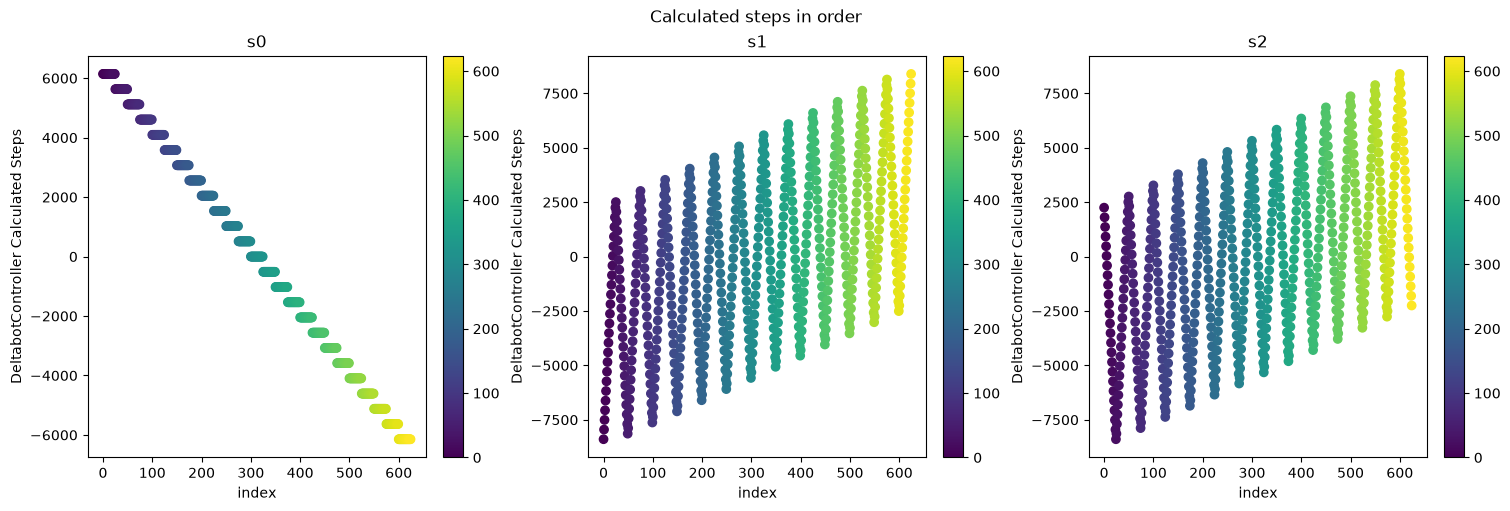

In [24]:
mesh0045_27Oct = pd.read_csv("processed_data/27Oct_0045_mesh.csv")
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor].index, mesh0045_27Oct[motor], c=mesh0045_27Oct.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("DeltabotController Calculated Steps")
    axs[i].set_title(motor)
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Calculated steps in order")

We can see that the s0 value is set for each row and we see the snaking behaviour of the s1 and s2 motors.

Find the max/min values of the motors so we can ensure the predicted values are within sensible limits.

In [25]:
# algorithm_steps
print("Calculated Motor Values Max/Min")
print(max(mesh0045_27Oct["s0"]))
print(max(mesh0045_27Oct["s1"]))
print(max(mesh0045_27Oct["s2"]))
print(min(mesh0045_27Oct["s0"]))
print(min(mesh0045_27Oct["s1"]))
print(min(mesh0045_27Oct["s2"]))

Calculated Motor Values Max/Min
6144.0
8393.0
8393.0
-6144.0
-8393.0
-8393.0


<h1> LR Predictions - Sklearn

In [26]:
#ensuring min and max motor values are sensible
#output
pred_snake_steps = pd.read_csv("predictions/all_data_LR_Pred_snake_mesh.csv", names=["s0", "s1", "s2"], dtype="float32")
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print("max s0 motor value: ", max(pred_snake_steps["s0"]))
print("max s1 motor value: ", max(pred_snake_steps["s1"]))
print("max s2 motor value: ", max(pred_snake_steps["s2"]))
print("min s0 motor value: ", min(pred_snake_steps["s0"]))
print("min s1 motor value: ", min(pred_snake_steps["s1"]))
print("min s2 motor value: ", min(pred_snake_steps["s2"]))

,s0,s1,s2
0,4575.481934,-5874.337891,1298.854492
1,4545.950684,-5566.870605,1020.918030
2,4516.419434,-5259.402832,742.981567
3,4486.888184,-4951.935059,465.045074
4,4457.356934,-4644.467285,187.108597


Predicted motor values Max/Min
max s0 motor value:  4575.48193359375
max s1 motor value:  6173.51611328125
max s2 motor value:  4957.86669921875
min s0 motor value:  -4460.9052734375
min s1 motor value:  -5874.337890625
min s2 motor value:  -5371.62109375


max/min values are within the limits of the algorithm calculated steps. 

Sum of motor values should = 0. Investigate: 

In [27]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print("highest motor sum (no adjustments): ", max(pred_snake_steps["sum_motors"]))
print("lowest motor sum (no adjustments): ", min(pred_snake_steps["sum_motors"]))


highest motor sum (no adjustments):  0.0020751953125
lowest motor sum (no adjustments):  -0.00189208984375


min and max sums are close to 0 - no need to adjust

Plotting predicted values from LR to look at 

Text(0.5, 0.98, 'Predictions from Standard Scaled Linear Regression on all data - Snake Scan')

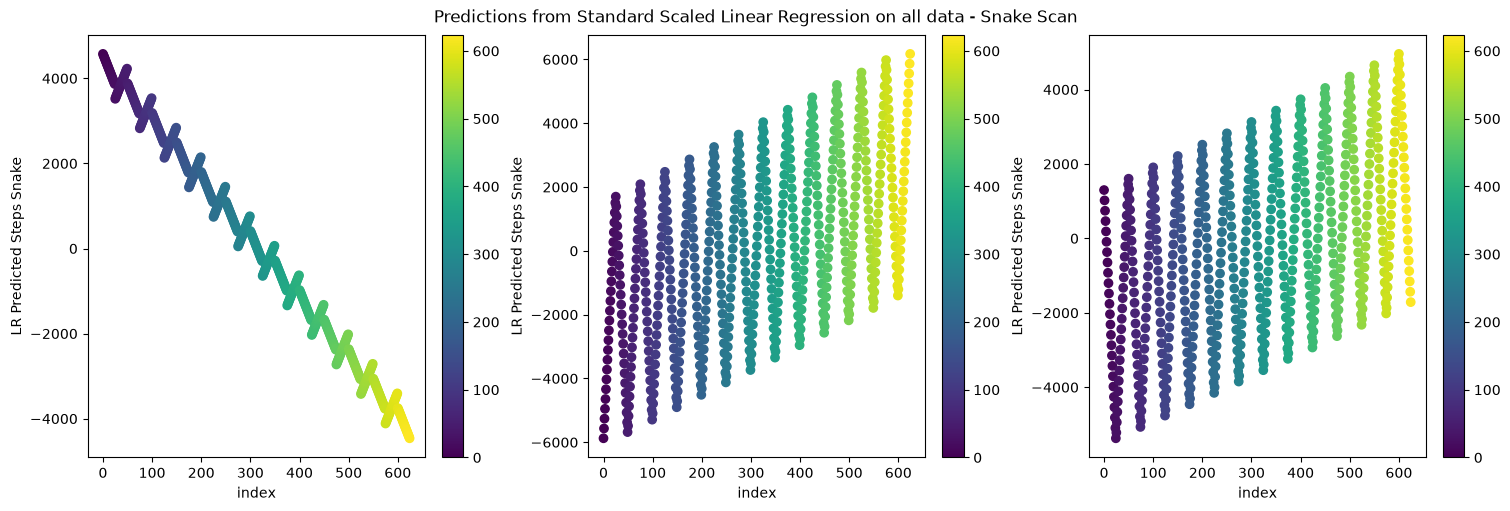

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("LR Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled Linear Regression on all data - Snake Scan")

<h2> Comparing the 2 datasets

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled Linear Regression (all data) Predictions for snake scan')

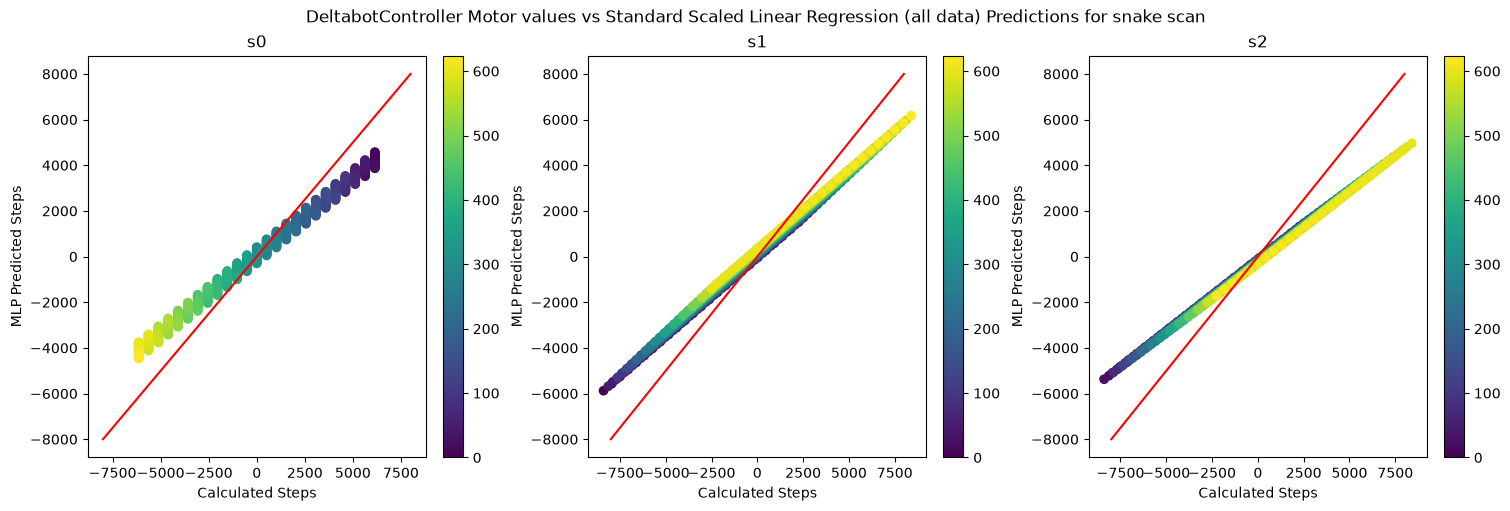

In [29]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[motor], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled Linear Regression (all data) Predictions for snake scan")

<h1>Output from Scan using predicted LR motor values

In [41]:
path = "scripts/scans/MLP"
scan = "0015_LR_all"

x_conversion = 0.1/11
y_conversion = x_conversion

start_cx = 318#px
start_cy = 260 #px

scan_LR = process_the_data(scan, path, x_conversion, y_conversion, start_cx, start_cy)
scan_LR.name = "scan_LR"

In [42]:
# scan_MLP

Text(0.5, 1.0, 'all data LR predictions scan')

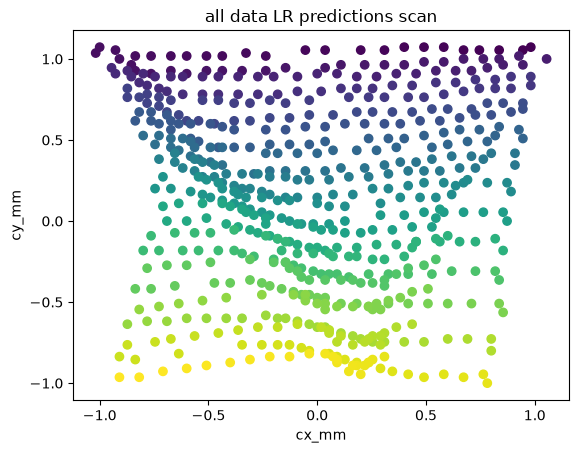

In [43]:
plt.scatter(scan_LR["cx_mm"], scan_LR["cy_mm"], c=scan_LR["point"])
plt.xlabel("cx_mm")
plt.ylabel("cy_mm")
plt.title(f"all data LR predictions scan")

Text(0.5, 0.98, 'Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by Linear Regression')

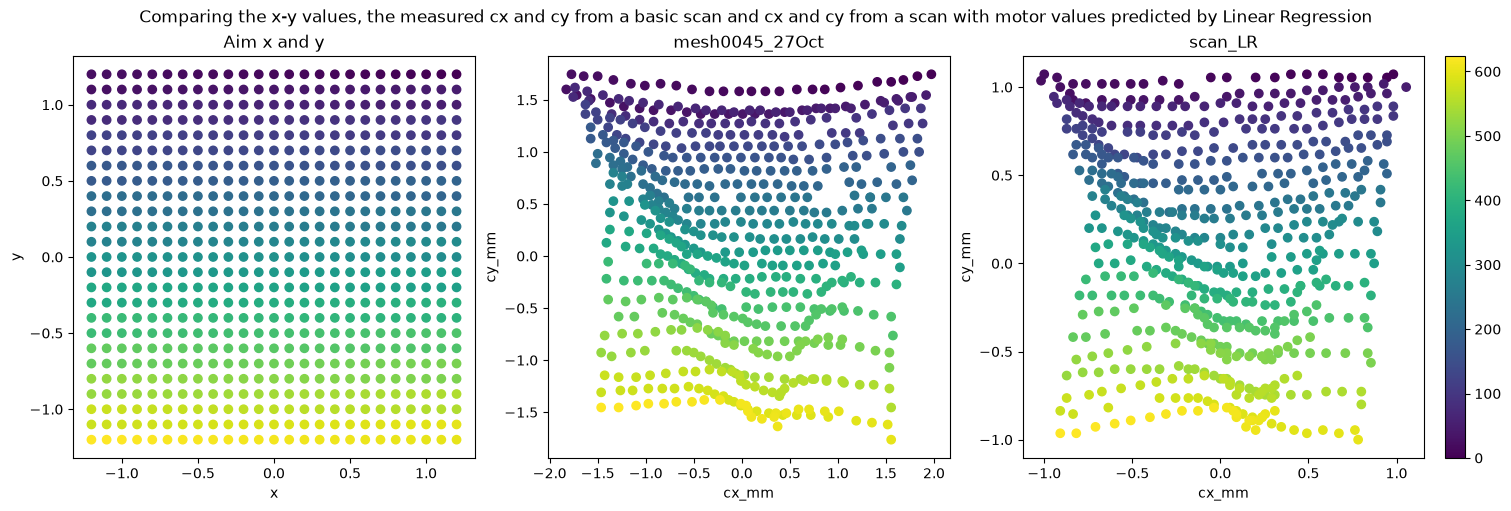

In [46]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)

im = axs[0].scatter(mesh0045_27Oct["x"], mesh0045_27Oct["y"], c=mesh0045_27Oct["point"])
axs[0].set_xlabel("x")
axs[0].set_ylabel("y")
axs[0].set_title("Aim x and y")

mesh0045_27Oct.name = "mesh0045_27Oct"
scan_LR.name = "scan_LR"
i = 1
for scan in mesh0045_27Oct, scan_LR:
    suplot = axs[i]
    suplot.scatter(scan["cx_mm"], scan["cy_mm"], c=scan["point"])
    suplot.set_xlabel("cx_mm")
    suplot.set_ylabel("cy_mm")
    # fig.colorbar(im, ax=axs[i])  
    suplot.set_title(scan.name)
    i = i+1

fig.colorbar(im, ax=axs[2])  
fig.suptitle("Comparing the x-y values, the measured cx and cy from a basic scan and cx and cy from a scan with motor values predicted by Linear Regression")

<h1>MLP

In [47]:
#gave those x and y values to the 16Oct MLP 
#output
pred_snake_steps = pd.read_csv("predictions/all_data_MLP_pred_snake.csv", names=["s0", "s1", "s2"], dtype="float32")
display(pred_snake_steps.head())
print("Predicted motor values Max/Min")
print(max(pred_snake_steps["s0"]))
print(max(pred_snake_steps["s1"]))
print(max(pred_snake_steps["s2"]))
print(min(pred_snake_steps["s0"]))
print(min(pred_snake_steps["s1"]))
print(min(pred_snake_steps["s2"]))

,s0,s1,s2
0,4905.798340,-5035.462402,333.834747
1,4907.667969,-4813.209961,91.471100
2,4909.537598,-4590.957520,-150.892532
3,4905.713867,-4367.614258,-387.680969
4,4898.683594,-4143.724121,-621.504822


Predicted motor values Max/Min
4978.64892578125
7290.69921875
5031.96044921875
-4671.955078125
-5035.46240234375
-5780.1748046875


In [48]:
pred_snake_steps['sum_motors'] = pred_snake_steps["s0"] + pred_snake_steps["s1"] + pred_snake_steps["s2"]
# display(pred_snake_steps['sum_motors'])
print("highest motor sum (no adjustments): ", max(pred_snake_steps["sum_motors"]))
print("lowest motor sum (no adjustments): ", min(pred_snake_steps["sum_motors"]))


pred_snake_steps["s0_adj"] = pred_snake_steps["s0"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s1_adj"] = pred_snake_steps["s1"] - (pred_snake_steps["sum_motors"]/3)
pred_snake_steps["s2_adj"] = pred_snake_steps["s2"] - (pred_snake_steps["sum_motors"]/3)

pred_snake_steps['sum_motors_adj'] = pred_snake_steps["s0_adj"] + pred_snake_steps["s1_adj"] + pred_snake_steps["s2_adj"]
# display(pred_snake_steps['sum_motors'])
print(max(pred_snake_steps["sum_motors_adj"]))
print(min(pred_snake_steps["sum_motors_adj"]))
print(max(pred_snake_steps["s0_adj"]))
print(max(pred_snake_steps["s1_adj"]))
print(max(pred_snake_steps["s2_adj"]))
print(min(pred_snake_steps["s0_adj"]))
print(min(pred_snake_steps["s1_adj"]))
print(min(pred_snake_steps["s2_adj"]))


highest motor sum (no adjustments):  207.53515625
lowest motor sum (no adjustments):  -13.5460205078125
0.00048828125
-0.00048828125
4935.205078125
7273.138671875
4962.7822265625
-4689.515625
-5103.51953125
-5824.5810546875


Text(0.5, 0.98, 'Predictions from Standard Scaled MLP on all data - Snake Scan')

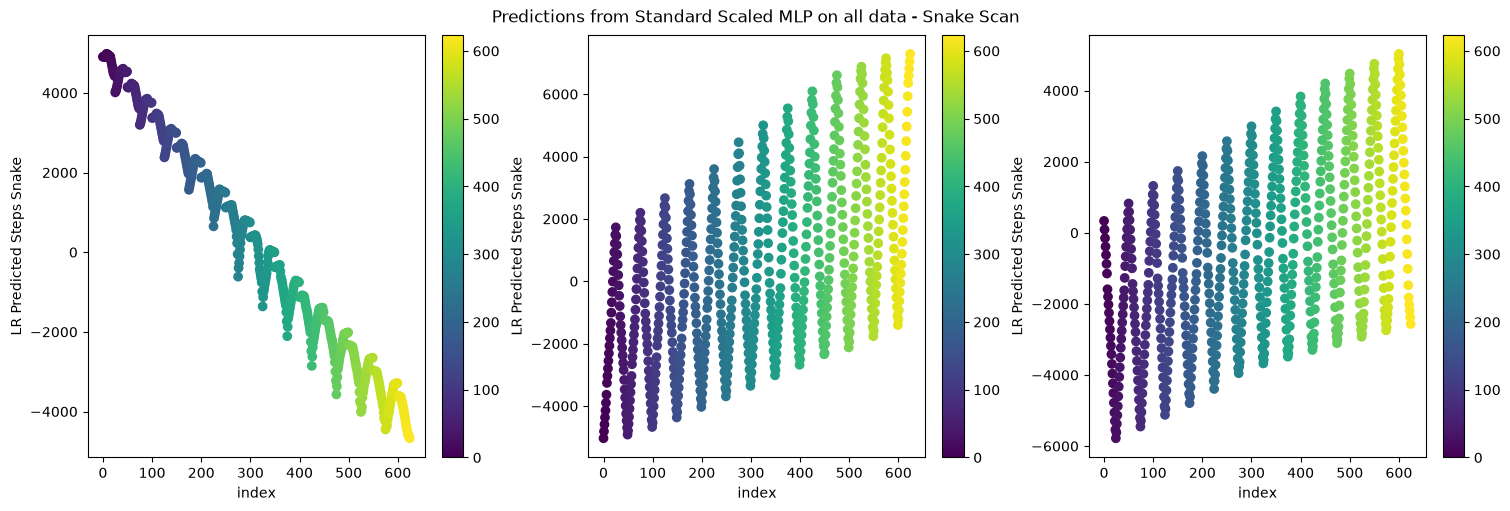

In [49]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("LR Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])  
fig.suptitle("Predictions from Standard Scaled MLP on all data - Snake Scan")

Text(0.5, 0.98, 'Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0')

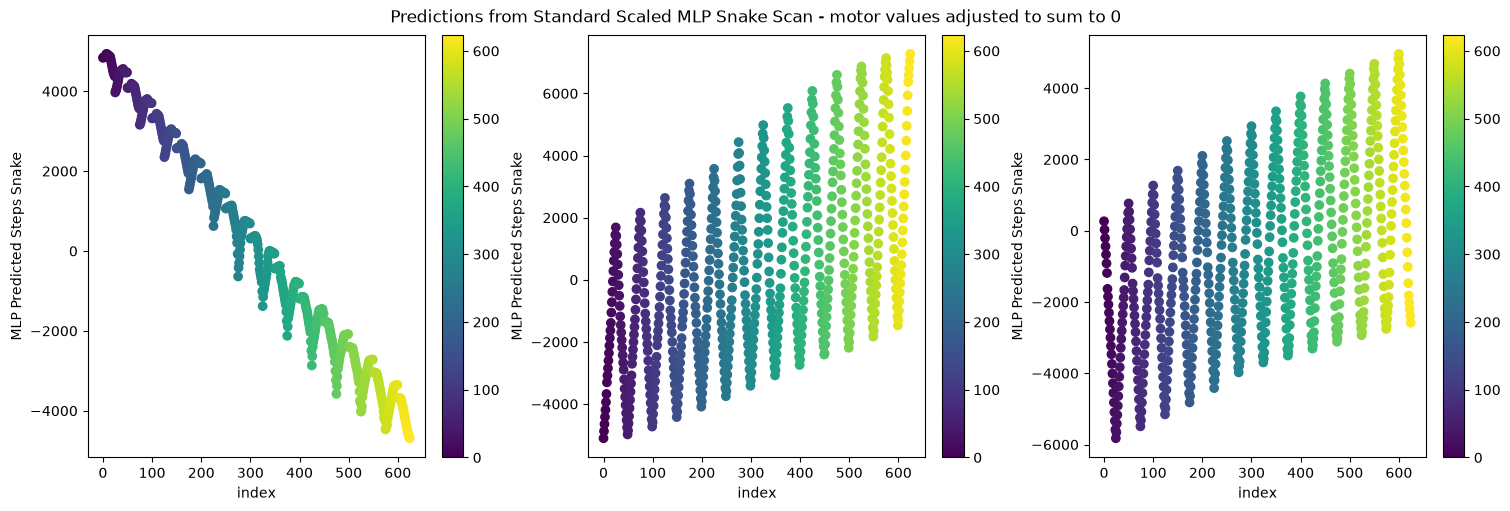

In [50]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0_adj", "s1_adj", "s2_adj"]):
    im = axs[i].scatter(pred_snake_steps[motor].index, pred_snake_steps[motor], c=pred_snake_steps.index)
    axs[i].set_xlabel("index")
    axs[i].set_ylabel("MLP Predicted Steps Snake")
    fig.colorbar(im, ax=axs[i])
fig.suptitle("Predictions from Standard Scaled MLP Snake Scan - motor values adjusted to sum to 0")

Text(0.5, 0.98, 'DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0')

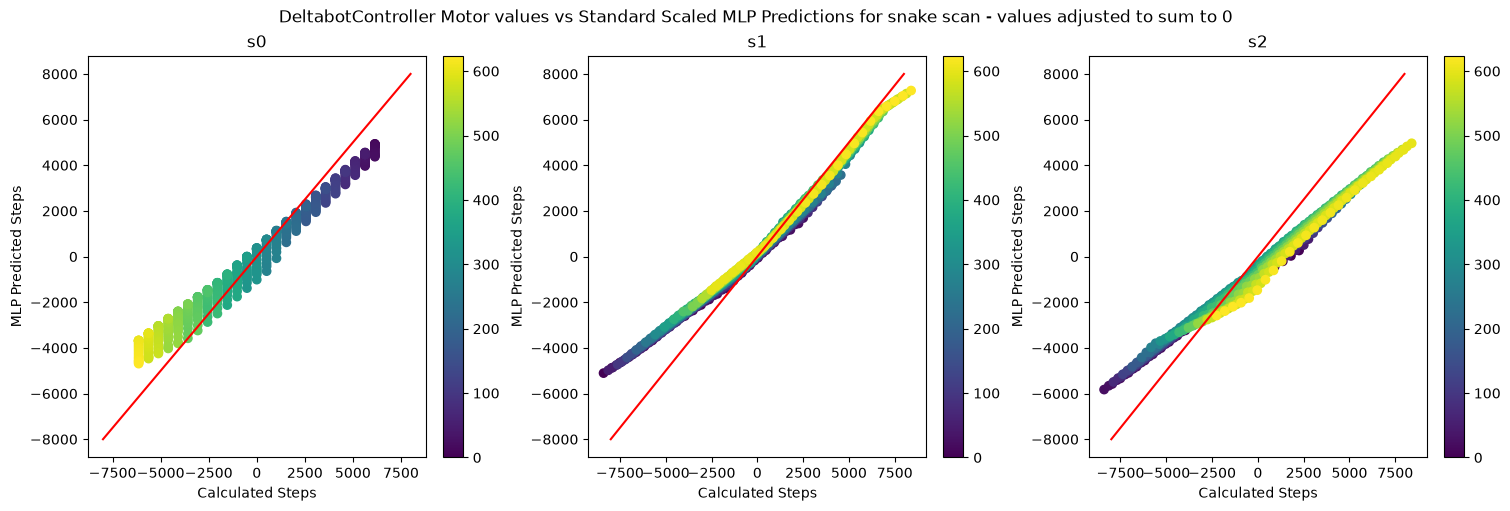

In [51]:
fig, axs = plt.subplots(1, 3, figsize=(15,5), constrained_layout=True)
for i, motor in enumerate(["s0", "s1", "s2"]):
    im = axs[i].scatter(mesh0045_27Oct[motor], pred_snake_steps[f"{motor}_adj"], c=mesh0045_27Oct["point"])
    axs[i].set_xlabel("Calculated Steps")
    axs[i].set_ylabel("MLP Predicted Steps")
    fig.colorbar(im, ax=axs[i])  
    axs[i].set_title(motor)
    lims = [-8000, 8000]
    # axs[i].set_xlim(lims)
    # axs[i].set_ylim(lims)
    _ = axs[i].plot(lims, lims, color="red")

fig.suptitle("DeltabotController Motor values vs Standard Scaled MLP Predictions for snake scan - values adjusted to sum to 0")

In [52]:
pred_snake_steps[["s0_adj", "s1_adj", "s2_adj"]].astype("int32").to_csv("predictions/adjusted_to_sum_to_0/all_data_MLP_Scaled_snake.csv", index=False)
data = pd.read_csv("predictions/adjusted_to_sum_to_0/all_data_MLP_Scaled_snake.csv")
# points = list(data.itertuples(index=False, name=None))
# print(points)
# # list(pred_snake_steps.itertuples(index=False, name=None))